# Projeto Integrado — Telemetria de Jogos
### Parte 4 — Análise complementar (Machine Learning)
**Equipe 4 | Big Data**

Baseada nas aulas 5 (Classificação), 6 (Regressão) e 7 (Clusterização). As três técnicas são **complementares**: avaliamos cada uma e justificamos quando ela faz ou não sentido para os dados do projeto.

| Técnica | Pergunta | Veredito (confirmado nas seções abaixo) |
|---|---|---|
| Classificação | Dá para prever o resultado de uma partida **antes** de ela acontecer? | Não. Sem as informações da própria partida, o modelo não supera o baseline |
| Regressão | Dá para estimar a pontuação de uma partida? | Sim, com desempenho moderado |
| Clusterização | Que perfis de jogadores existem? | Sim, como segmentação exploratória |

## 1. Importação das bibliotecas

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             mean_squared_error, mean_absolute_error, r2_score,
                             silhouette_score, davies_bouldin_score)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

## 2. Carregando os dados
Usamos os CSVs **já tratados pelo ETL** (`data_lake/processed`).

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Ajuste o caminho para a pasta onde estão os CSVs tratados
PASTA = '/content/drive/MyDrive/PI_telemetria_de_jogos/'

jogadores     = pd.read_csv(PASTA + 'jogadores_limpo.csv')
sessoes       = pd.read_csv(PASTA + 'sessoes_limpo.csv')
partidas      = pd.read_csv(PASTA + 'partidas_limpo.csv')
compras       = pd.read_csv(PASTA + 'compras_limpo.csv')
itens_compras = pd.read_csv(PASTA + 'itens_compras_limpo.csv')

print('jogadores:', jogadores.shape, '| sessões:', sessoes.shape, '| partidas:', partidas.shape)
print('compras:', compras.shape, '| itens_compras:', itens_compras.shape)

jogadores: (1000, 11) | sessões: (37366, 9) | partidas: (58312, 8)
compras: (1425, 3) | itens_compras: (1963, 8)


In [4]:
# Verificação rápida: os dados já passaram pelo ETL, então não devem ter duplicados
print('IDs duplicados -> jogadores:', jogadores.player_id.duplicated().sum(),
      '| sessões:', sessoes.sessao_id.duplicated().sum(),
      '| partidas:', partidas.partida_id.duplicated().sum())
print('Plataformas:', sessoes.plataforma.unique())
print('Resultados:', partidas.resultado.unique())

IDs duplicados -> jogadores: 0 | sessões: 0 | partidas: 0
Plataformas: ['PlayStation' 'PC' 'Xbox' 'Mobile']
Resultados: ['Vitória' 'Derrota' 'Empate']


## 3. Tabela por partida
Cada linha é uma partida, com o contexto da sessão e do jogador. Será usada na classificação e na regressão.

In [5]:
df_partida = (partidas
    .merge(sessoes[['sessao_id', 'player_id', 'plataforma', 'genero_jogo', 'nivel_inicio']], on='sessao_id')
    .merge(jogadores[['player_id', 'idade', 'nivel_jogador']], on='player_id')
    .dropna(subset=['resultado']))

print(df_partida.shape)
df_partida[['partida_id', 'plataforma', 'genero_jogo', 'idade', 'nivel_inicio', 'duracao_minutos',
            'resultado', 'pontuacao', 'experiencia_ganha']].head()

(58312, 14)


,partida_id,plataforma,genero_jogo,idade,nivel_inicio,duracao_minutos,resultado,pontuacao,experiencia_ganha
0,1,PlayStation,Aventura,35,1,57,Vitória,1145,603
1,2,PC,Simulação,35,5,72,Derrota,1440,216
2,3,PC,Simulação,35,5,61,Derrota,1403,366
3,4,PlayStation,Simulação,35,9,48,Derrota,1104,288
4,5,PlayStation,Simulação,35,9,65,Vitória,1249,452


## 4. Classificação — prever o resultado da partida
**Pergunta:** dá para prever se o jogador vai ganhar, perder ou empatar?

O ponto principal é **quais informações o modelo pode usar**. Para prever *antes* da partida só valem dados conhecidos antes dela. `pontuacao` e `experiencia_ganha` só existem depois que a partida termina, então usá-las seria **vazamento de dados** (*data leakage*).

Vamos comparar os dois cenários (padrão da Aula 5: Pipeline + RandomForest) com um **baseline** que sempre chuta a classe mais comum.

In [6]:
def treinar_classificador(features, nome):
    X = df_partida[features]
    Y = df_partida['resultado']
    num = X.select_dtypes(include=['int64', 'float64']).columns
    cat = X.select_dtypes(include=['object', 'category', 'string']).columns

    preprocessor = ColumnTransformer(transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat)
    ])
    pipe = Pipeline([('preprocessor', preprocessor),
                     ('classifier', RandomForestClassifier(n_estimators=100, min_samples_leaf=10,
                                                           random_state=42, n_jobs=-1))])
    X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    return {'Cenário': nome,
            'Acurácia': accuracy_score(y_test, y_pred),
            'Precisão': precision_score(y_test, y_pred, average='macro', zero_division=0),
            'Recall': recall_score(y_test, y_pred, average='macro'),
            'F1-Score': f1_score(y_test, y_pred, average='macro')}, y_test

# Cenário A: só informações conhecidas ANTES da partida
antes = ['idade', 'nivel_jogador', 'nivel_inicio', 'plataforma', 'genero_jogo']
# Cenário B: inclui informações que só existem DEPOIS (vazamento)
depois = antes + ['pontuacao', 'experiencia_ganha']

res_a, y_test = treinar_classificador(antes, 'A) Antes da partida')
res_b, _ = treinar_classificador(depois, 'B) Com pontuação e XP (vazamento)')
baseline = {'Cenário': 'Baseline (classe mais comum)',
            'Acurácia': y_test.value_counts(normalize=True).max(),
            'Precisão': np.nan, 'Recall': np.nan, 'F1-Score': np.nan}

pd.DataFrame([baseline, res_a, res_b]).round(3)

,Cenário,Acurácia,Precisão,Recall,F1-Score
0,Baseline (classe mais comum),0.471,NaN,NaN,NaN
1,A) Antes da partida,0.467,0.312,0.331,0.321
2,B) Com pontuação e XP (vazamento),0.734,0.490,0.520,0.504


**Conclusão da classificação:**
- No **cenário A** (o único realista para prever antes da partida), o modelo fica praticamente igual ao baseline: nada do que se sabe antes da partida indica quem vai vencer. Isso é coerente com dados em que o resultado não depende de perfil, plataforma ou gênero.
- O **cenário B** tem acurácia bem acima do baseline, mas é enganoso, pois pontuação e XP **dependem** do resultado (vitórias rendem mais pontos e XP).
- Portanto, a **classificação não é recomendada** neste projeto como ferramenta de previsão.

## 5. Regressão — estimar a pontuação da partida
**Pergunta:** dá para estimar a pontuação a partir da duração, do nível, da idade, da plataforma e do gênero do jogo? (Padrão da Aula 6: Pipeline + RandomForestRegressor.)

In [7]:
features = ['duracao_minutos', 'nivel_inicio', 'idade', 'plataforma', 'genero_jogo']
X = df_partida[features]
Y = df_partida['pontuacao']

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object', 'category', 'string']).columns

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

pipeline_reg = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, min_samples_leaf=10, random_state=42, n_jobs=-1))
])
pipeline_reg.fit(X_train, y_train)

baseline_reg = DummyRegressor(strategy='mean').fit(X_train, y_train)

In [9]:
linhas = []
for nome, modelo in [('Baseline (média)', baseline_reg), ('RandomForest', pipeline_reg)]:
    y_pred = modelo.predict(X_test)
    linhas.append({'Modelo': nome,
                   'MSE': mean_squared_error(y_test, y_pred),
                   'MAE': mean_absolute_error(y_test, y_pred),
                   'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
                   'R²': r2_score(y_test, y_pred)})
pd.DataFrame(linhas).round(3)

,Modelo,MSE,MAE,RMSE,R²
0,Baseline (média),186014.890,336.458,431.294,-0.000
1,RandomForest,83887.009,231.702,289.633,0.549


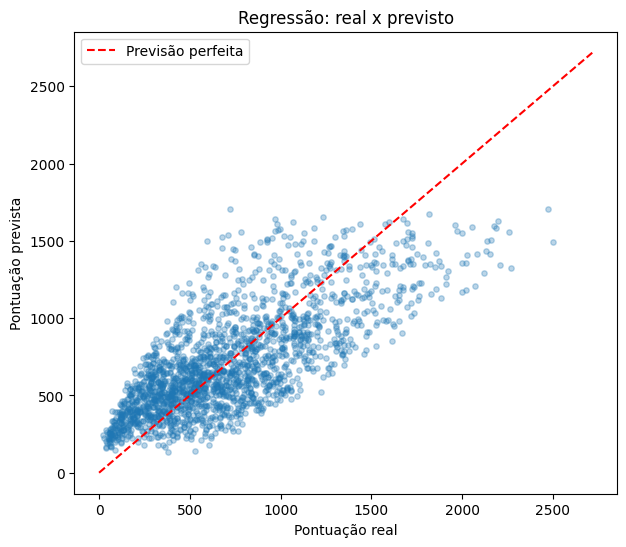

In [10]:
# Real x previsto (amostra de 2.000 partidas do conjunto de teste)
y_pred = pipeline_reg.predict(X_test)
amostra = np.random.RandomState(42).choice(len(y_test), 2000, replace=False)

plt.figure(figsize=(7, 6))
plt.scatter(y_test.values[amostra], y_pred[amostra], alpha=0.3, s=15)
lim = [0, y_test.max()]
plt.plot(lim, lim, 'r--', label='Previsão perfeita')
plt.xlabel('Pontuação real'); plt.ylabel('Pontuação prevista')
plt.title('Regressão: real x previsto'); plt.legend(); plt.show()

In [11]:
# Testando uma nova entrada (como na aula): partida de 60 min no PC
nova = df_partida[features].iloc[[0]].copy()
nova['duracao_minutos'] = 60
nova['plataforma'] = 'PC'

resultado = nova.T.reset_index()
resultado.columns = ['Variável', 'Valor']
resultado.loc[len(resultado)] = ['Pontuação prevista', f'{pipeline_reg.predict(nova)[0]:.0f}']
resultado

,Variável,Valor
0,duracao_minutos,60
1,nivel_inicio,1
2,idade,35
3,plataforma,PC
4,genero_jogo,Aventura
5,Pontuação prevista,1253


In [12]:
# Quanto a pontuação média cresce com a duração da partida?
df_partida['faixa_duracao'] = pd.cut(df_partida['duracao_minutos'], bins=[0, 15, 30, 45, 60, 300])
df_partida.groupby('faixa_duracao', observed=True)['pontuacao'].mean().round(0)

,pontuacao
faixa_duracao,
"(0, 15]",329.0
"(15, 30]",545.0
"(30, 45]",789.0
"(45, 60]",1025.0
"(60, 300]",1380.0


**Conclusão da regressão:** o R² mostra que o modelo explica uma parte relevante da variação da pontuação, bem acima do baseline, e o gráfico real x previsto segue a diagonal, com dispersão. A principal variável é a **duração da partida** (quanto mais longa, maior a pontuação). O erro (MAE) ainda é considerável, então o modelo serve para **estimar a pontuação esperada**, não para prever valores exatos. A **regressão é viável** neste projeto.

## 6. Clusterização — perfis de jogadores
Não precisamos de um alvo: o KMeans (Aula 7) agrupa jogadores parecidos entre si. Montamos uma tabela com **1 linha por jogador** que resume o comportamento.

In [13]:
sessoes['ganho_nivel'] = sessoes['nivel_fim'] - sessoes['nivel_inicio']
res_sessoes = sessoes.groupby('player_id').agg(
    n_sessoes=('sessao_id', 'count'),
    duracao_media_sessao=('duracao_minutos', 'mean'),
    ganho_nivel_medio=('ganho_nivel', 'mean')
)

partidas_j = partidas.merge(sessoes[['sessao_id', 'player_id']], on='sessao_id')
res_partidas = partidas_j.groupby('player_id').agg(
    pontuacao_media=('pontuacao', 'mean'),
    taxa_vitoria=('resultado', lambda x: (x == 'Vitória').mean())
)

compras_j = compras.merge(sessoes[['sessao_id', 'player_id']], on='sessao_id')
res_gasto = (itens_compras.merge(compras_j[['compra_id', 'player_id']], on='compra_id')
             .groupby('player_id').agg(gasto_total=('valor_total_item', 'sum')))

df = (jogadores[['player_id', 'idade', 'nivel_jogador']]
      .merge(res_sessoes, on='player_id', how='left')
      .merge(res_partidas, on='player_id', how='left')
      .merge(res_gasto, on='player_id', how='left'))
df['gasto_total'] = df['gasto_total'].fillna(0)   # quem não comprou gastou 0
df['pagante'] = (df['gasto_total'] > 0).astype(int)
df.describe().round(2)

,player_id,idade,nivel_jogador,n_sessoes,duracao_media_sessao,ganho_nivel_medio,pontuacao_media,taxa_vitoria,gasto_total,pagante
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,500.50,35.45,50.52,37.37,100.49,2.15,700.33,0.47,42.75,0.36
std,288.82,11.59,28.63,22.45,27.21,3.65,170.66,0.08,100.43,0.48
min,1.00,16.00,1.00,1.00,47.52,0.00,261.64,0.00,0.00,0.00
25%,250.75,26.00,25.00,21.75,78.93,0.67,577.33,0.42,0.00,0.00
50%,500.50,36.00,51.00,33.00,98.21,1.41,700.38,0.47,0.00,0.00
75%,750.25,45.00,76.00,49.00,118.84,2.46,826.23,0.51,42.34,1.00
max,1000.00,55.00,100.00,176.00,207.20,77.00,1307.50,1.00,1120.89,1.00


In [14]:
cluster_features = ['idade', 'nivel_jogador', 'n_sessoes', 'duracao_media_sessao',
                    'ganho_nivel_medio', 'pontuacao_media', 'taxa_vitoria', 'gasto_total']
df = df.dropna(subset=cluster_features).reset_index(drop=True)
Xc = df[cluster_features].copy()

# log1p reduz o peso dos valores extremos (variáveis muito assimétricas)
for col in ['n_sessoes', 'ganho_nivel_medio', 'gasto_total']:
    Xc[col] = np.log1p(Xc[col])

In [15]:
numeric_features = Xc.columns
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
preprocessor = ColumnTransformer(transformers=[('num', numeric_transformer, numeric_features)])
X_preprocessed = preprocessor.fit_transform(Xc)

### 6.1 Escolhendo o número de clusters (k)

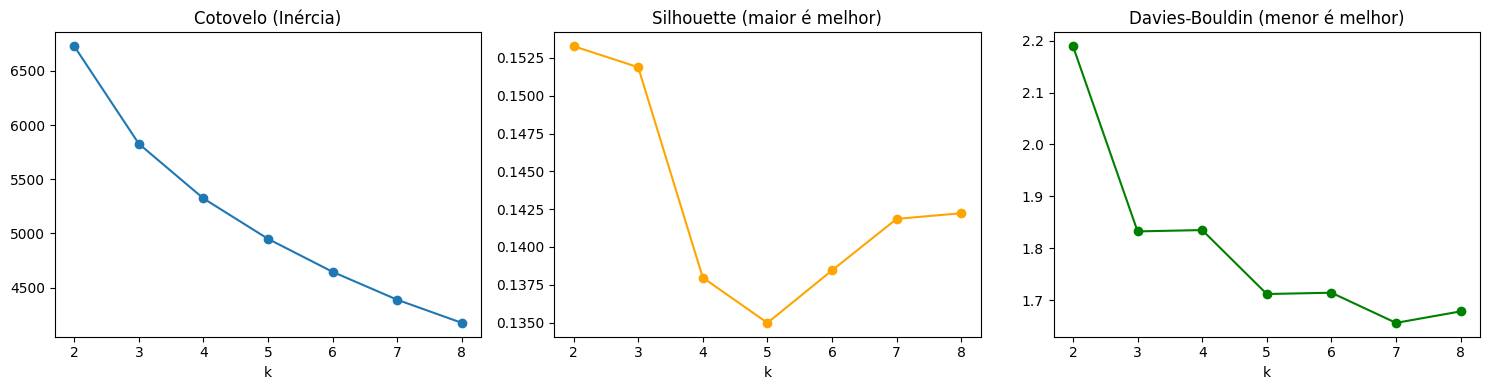

,k,Silhouette,Davies-Bouldin
0,2,0.153,2.189
1,3,0.152,1.832
2,4,0.138,1.835
3,5,0.135,1.712
4,6,0.138,1.714
5,7,0.142,1.656
6,8,0.142,1.678


In [16]:
ks = range(2, 9)
inercias, silhuetas, davies = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lab = km.fit_predict(X_preprocessed)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(X_preprocessed, lab))
    davies.append(davies_bouldin_score(X_preprocessed, lab))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(ks, inercias, marker='o'); ax[0].set_title('Cotovelo (Inércia)')
ax[1].plot(ks, silhuetas, marker='o', color='orange'); ax[1].set_title('Silhouette (maior é melhor)')
ax[2].plot(ks, davies, marker='o', color='green'); ax[2].set_title('Davies-Bouldin (menor é melhor)')
for a in ax: a.set_xlabel('k')
plt.tight_layout(); plt.show()

pd.DataFrame({'k': list(ks), 'Silhouette': silhuetas, 'Davies-Bouldin': davies}).round(3)

**Escolha do k:** o Silhouette é baixo em todos os valores de k, sem um "cotovelo" claro, o que indica grupos pouco separados. Usamos **k = 4** como compromisso entre o Davies-Bouldin (que melhora com mais grupos) e uma quantidade de perfis fácil de interpretar para o negócio.

### 6.2 Treinando o modelo final

In [17]:
k = 4
model = KMeans(n_clusters=k, random_state=42, n_init=10)
pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('cluster', model)])
pipeline.fit(Xc)

labels = pipeline.predict(Xc)
df['cluster'] = labels

print(f'Silhouette Score: {silhouette_score(X_preprocessed, labels):.3f}  # varia de -1 a 1')
print(f'Inércia: {model.inertia_:.1f}')
print(f'Davies-Bouldin: {davies_bouldin_score(X_preprocessed, labels):.3f}  # quanto menor, melhor')
print()
print(df['cluster'].value_counts().sort_index())

Silhouette Score: 0.138  # varia de -1 a 1
Inércia: 5322.5
Davies-Bouldin: 1.835  # quanto menor, melhor

cluster
0    270
1    266
2    269
3    195
Name: count, dtype: int64


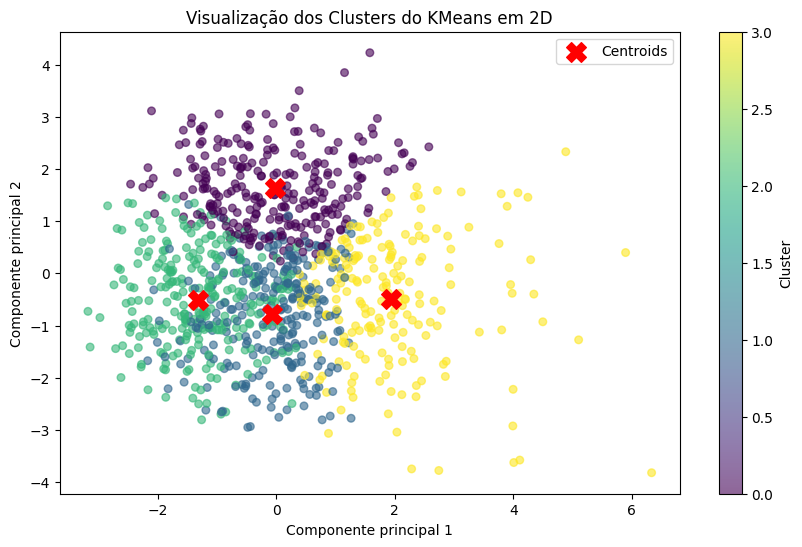

In [18]:
# Visualização em 2D com PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_preprocessed)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis', s=30, alpha=0.6)
centroids = pca.transform(model.cluster_centers_)
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=200, label='Centroids')
plt.colorbar(scatter, label='Cluster')
plt.xlabel('Componente principal 1'); plt.ylabel('Componente principal 2')
plt.title('Visualização dos Clusters do KMeans em 2D'); plt.legend(); plt.show()

### 6.3 Interpretando os perfis

In [19]:
perfil = df.groupby('cluster')[cluster_features].mean().round(2)
perfil['qtd_jogadores'] = df['cluster'].value_counts().sort_index()
perfil['%_pagantes'] = (df.groupby('cluster')['pagante'].mean() * 100).round(1)
perfil

,idade,nivel_jogador,n_sessoes,duracao_media_sessao,ganho_nivel_medio,pontuacao_media,taxa_vitoria,gasto_total,qtd_jogadores,%_pagantes
cluster,,,,,,,,,,
0,34.66,43.49,39.22,131.02,1.28,890.48,0.47,43.75,270,36.7
1,35.83,74.56,48.99,86.47,1.76,614.68,0.47,73.48,266,51.5
2,36.49,21.22,40.23,83.87,0.63,599.82,0.47,30.66,269,28.3
3,34.57,67.90,15.00,100.28,5.97,692.55,0.46,16.14,195,25.6


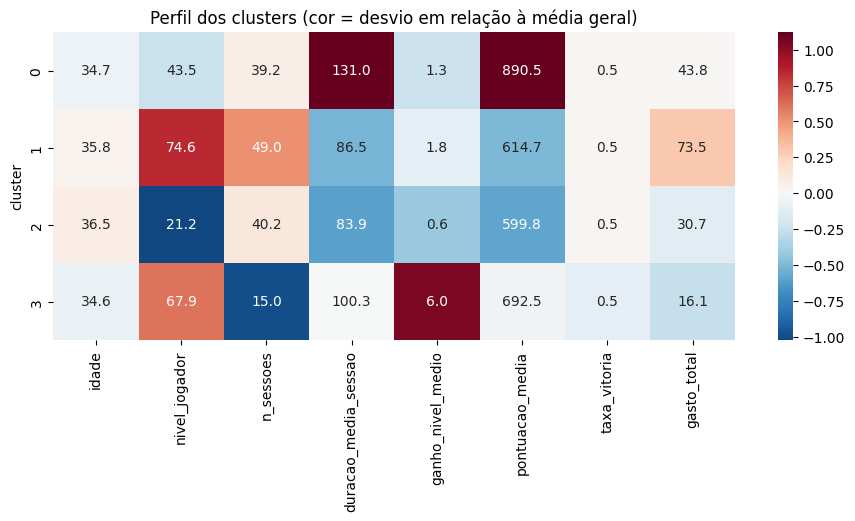

Cluster 0 (270 jogadores, 37% pagantes): acima da média em duracao_media_sessao, pontuacao_media; abaixo da média em nivel_jogador, ganho_nivel_medio.
Cluster 1 (266 jogadores, 52% pagantes): acima da média em nivel_jogador, n_sessoes; abaixo da média em duracao_media_sessao, pontuacao_media.
Cluster 2 (269 jogadores, 28% pagantes): acima da média em n_sessoes, idade; abaixo da média em nivel_jogador, duracao_media_sessao.
Cluster 3 (195 jogadores, 26% pagantes): acima da média em ganho_nivel_medio, nivel_jogador; abaixo da média em n_sessoes, gasto_total.


In [20]:
# Mapa de calor: desvio de cada cluster em relação à média geral (cor) com o valor real (número)
z = (perfil[cluster_features] - df[cluster_features].mean()) / df[cluster_features].std()

plt.figure(figsize=(11, 4))
sns.heatmap(z, annot=perfil[cluster_features], fmt='.1f', cmap='RdBu_r', center=0)
plt.title('Perfil dos clusters (cor = desvio em relação à média geral)')
plt.show()

# Resumo em texto: o que mais destaca cada cluster
for c in z.index:
    altos = z.loc[c].sort_values(ascending=False).head(2)
    baixos = z.loc[c].sort_values().head(2)
    print(f"Cluster {c} ({int(perfil.loc[c, 'qtd_jogadores'])} jogadores, {perfil.loc[c, '%_pagantes']:.0f}% pagantes): "
          f"acima da média em {', '.join(altos.index)}; abaixo da média em {', '.join(baixos.index)}.")

## 7. Conclusão
- **Classificação:** avaliada e descartada. Antes da partida não há informação que antecipe o resultado; o bom desempenho só aparece com vazamento de dados.
- **Regressão:** viável. Estima a pontuação esperada de uma partida, principalmente a partir da duração. Serve para *estimar*, não para prever valores exatos.
- **Clusterização:** adequada, pois não exige alvo. Revela perfis de jogadores (tabela e mapa de calor da seção 6.3), que podem apoiar campanhas de retenção, ofertas de itens e comunicação segmentada.

> **Limitação:** o Silhouette Score baixo indica grupos com fronteiras **sobrepostas**, comum em dados de comportamento. Os perfis devem ser usados como **segmentação exploratória**, não como categorias rígidas.